In [2]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
from src.config import Config
from src.utils.seed import set_seed
from src.utils.io_helpers import save_checkpoint, save_json
from src.dataset import get_dataloaders
from src.models.vanilla_ae import VanillaAutoencoder
from src.trainers.train_ae import train_deterministic_ae
from src.evaluation.metrics import evaluate_ae_on_testset

set_seed(Config.SEED)
Config.ensure_dirs()
train_loader, val_loader, test_loader = get_dataloaders(batch_size=Config.BATCH_SIZE, seed=Config.SEED, num_workers=0)

vanilla_ae = VanillaAutoencoder(
    input_dim=Config.INPUT_DIM,
    hidden_dim=256,
    latent_dim=Config.AE_LATENT_DIM,
)

train_out = train_deterministic_ae(
    model=vanilla_ae,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=Config.AE_EPOCHS,
    lr=Config.AE_LR,
    device=Config.DEVICE,
    l1_lambda=0.0,
    model_name="Vanilla AE",
)

test_metrics, latency_ms = evaluate_ae_on_testset(vanilla_ae, test_loader, Config.DEVICE, is_vae=False)
print(f"Vanilla AE Test Metrics: {test_metrics} | Latency (batch=64): {latency_ms} ms")

save_checkpoint(vanilla_ae, Config.CHECKPOINT_DIR / "vanilla_ae.pth")
save_json(
    {
        "model": "Vanilla Autoencoder",
        "latent_dim": Config.AE_LATENT_DIM,
        "avg_epoch_time_sec": train_out["avg_epoch_time_sec"],
        "inference_latency_ms_batch64": latency_ms,
        "test_metrics": test_metrics,
        "history": train_out["history"],
    },
    Config.METRICS_DIR / "vanilla_ae_results.json",
)

[Vanilla AE] Epoch 01/30 | Train Loss: 0.034935 (MSE: 0.034935) | Val MSE: 0.020088 | Time: 7.93s
[Vanilla AE] Epoch 05/30 | Train Loss: 0.012423 (MSE: 0.012423) | Val MSE: 0.012216 | Time: 7.51s
[Vanilla AE] Epoch 10/30 | Train Loss: 0.009949 (MSE: 0.009949) | Val MSE: 0.010182 | Time: 7.44s
[Vanilla AE] Epoch 15/30 | Train Loss: 0.008975 (MSE: 0.008975) | Val MSE: 0.009350 | Time: 8.39s
[Vanilla AE] Epoch 20/30 | Train Loss: 0.008480 (MSE: 0.008480) | Val MSE: 0.008813 | Time: 8.46s
[Vanilla AE] Epoch 25/30 | Train Loss: 0.008174 (MSE: 0.008174) | Val MSE: 0.008482 | Time: 9.01s
[Vanilla AE] Epoch 30/30 | Train Loss: 0.007970 (MSE: 0.007970) | Val MSE: 0.008295 | Time: 8.17s
Vanilla AE Test Metrics: {'mse': 0.008242, 'psnr': 20.8399, 'ssim': 0.836, 'latent_zero_ratio': 0.3615} | Latency (batch=64): 0.7173 ms


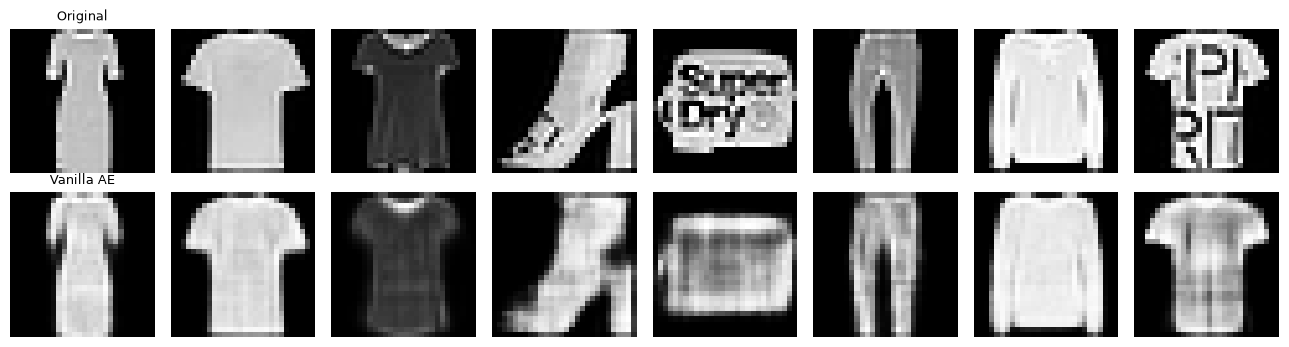

In [3]:
sample_x, _ = next(iter(test_loader))
sample_x = sample_x[:8].to(Config.DEVICE)
recon_x, _ = vanilla_ae(sample_x)

fig, axes = plt.subplots(2, 8, figsize=(13, 3.5))
for i in range(8):
    axes[0, i].imshow(sample_x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(recon_x[i].detach().cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_title("Original", fontsize=9)
axes[1, 0].set_title("Vanilla AE", fontsize=9)
plt.tight_layout()
plt.show()